In [1]:
import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

import matplotlib.pyplot as plt
from torch.utils.data.dataset import _T_co

from tqdm import tqdm

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

import seaborn as sns

In [2]:
np.random.seed(42)
torch.manual_seed(42)

In [3]:
data = pd.read_csv('framingham.csv')

In [4]:
data.head()

,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4.0,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,2.0,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,1,48,1.0,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,0,61,3.0,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,0,46,3.0,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0


In [6]:
data.sample(5)

,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
4044,0,39,1.0,0,0.0,0.0,0,0,0,195.0,129.5,93.5,34.84,85.0,85.0,0
4073,1,51,1.0,1,30.0,0.0,0,0,0,241.0,118.0,79.0,20.09,70.0,56.0,0
1728,0,46,1.0,0,0.0,0.0,0,1,0,239.0,166.5,107.0,19.27,110.0,70.0,0
453,0,47,1.0,0,0.0,0.0,0,0,0,234.0,127.5,83.5,27.65,85.0,89.0,0
748,1,42,2.0,0,0.0,0.0,0,1,0,249.0,142.5,90.0,26.14,59.0,82.0,0


In [7]:
data.tail()

,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
4233,1,50,1.0,1,1.0,0.0,0,1,0,313.0,179.0,92.0,25.97,66.0,86.0,1
4234,1,51,3.0,1,43.0,0.0,0,0,0,207.0,126.5,80.0,19.71,65.0,68.0,0
4235,0,48,2.0,1,20.0,NaN,0,0,0,248.0,131.0,72.0,22.00,84.0,86.0,0
4236,0,44,1.0,1,15.0,0.0,0,0,0,210.0,126.5,87.0,19.16,86.0,NaN,0
4237,0,52,2.0,0,0.0,0.0,0,0,0,269.0,133.5,83.0,21.47,80.0,107.0,0


In [8]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 4238 entries, 0 to 4237
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   male             4238 non-null   int64  
 1   age              4238 non-null   int64  
 2   education        4133 non-null   float64
 3   currentSmoker    4238 non-null   int64  
 4   cigsPerDay       4209 non-null   float64
 5   BPMeds           4185 non-null   float64
 6   prevalentStroke  4238 non-null   int64  
 7   prevalentHyp     4238 non-null   int64  
 8   diabetes         4238 non-null   int64  
 9   totChol          4188 non-null   float64
 10  sysBP            4238 non-null   float64
 11  diaBP            4238 non-null   float64
 12  BMI              4219 non-null   float64
 13  heartRate        4237 non-null   float64
 14  glucose          3850 non-null   float64
 15  TenYearCHD       4238 non-null   int64  
dtypes: float64(9), int64(7)
memory usage: 529.9 KB


In [9]:
data.describe()

,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
count,4238.000000,4238.000000,4133.000000,4238.000000,4209.000000,4185.000000,4238.000000,4238.000000,4238.000000,4188.000000,4238.000000,4238.000000,4219.000000,4237.000000,3850.000000,4238.000000
mean,0.429212,49.584946,1.978950,0.494101,9.003089,0.029630,0.005899,0.310524,0.025720,236.721585,132.352407,82.893464,25.802008,75.878924,81.966753,0.151958
std,0.495022,8.572160,1.019791,0.500024,11.920094,0.169584,0.076587,0.462763,0.158316,44.590334,22.038097,11.910850,4.080111,12.026596,23.959998,0.359023
min,0.000000,32.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,107.000000,83.500000,48.000000,15.540000,44.000000,40.000000,0.000000
25%,0.000000,42.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,206.000000,117.000000,75.000000,23.070000,68.000000,71.000000,0.000000
50%,0.000000,49.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,234.000000,128.000000,82.000000,25.400000,75.000000,78.000000,0.000000
75%,1.000000,56.000000,3.000000,1.000000,20.000000,0.000000,0.000000,1.000000,0.000000,263.000000,144.000000,89.875000,28.040000,83.000000,87.000000,0.000000
max,1.000000,70.000000,4.000000,1.000000,70.000000,1.000000,1.000000,1.000000,1.000000,696.000000,295.000000,142.500000,56.800000,143.000000,394.000000,1.000000


In [10]:
data.isnull().sum()

male                 0
age                  0
education          105
currentSmoker        0
cigsPerDay          29
BPMeds              53
prevalentStroke      0
prevalentHyp         0
diabetes             0
totChol             50
sysBP                0
diaBP                0
BMI                 19
heartRate            1
glucose            388
TenYearCHD           0
dtype: int64

In [11]:
data = data.replace('NA', np.nan)
numeric_columns = ['education', 'cigsPerDay', 'BPMeds', 'totChol', 'BMI', 'heartRate', 'glucose']
for col in numeric_columns:
    data[col] = pd.to_numeric(data[col], errors='coerce')
data.isnull().sum()

male                 0
age                  0
education          105
currentSmoker        0
cigsPerDay          29
BPMeds              53
prevalentStroke      0
prevalentHyp         0
diabetes             0
totChol             50
sysBP                0
diaBP                0
BMI                 19
heartRate            1
glucose            388
TenYearCHD           0
dtype: int64

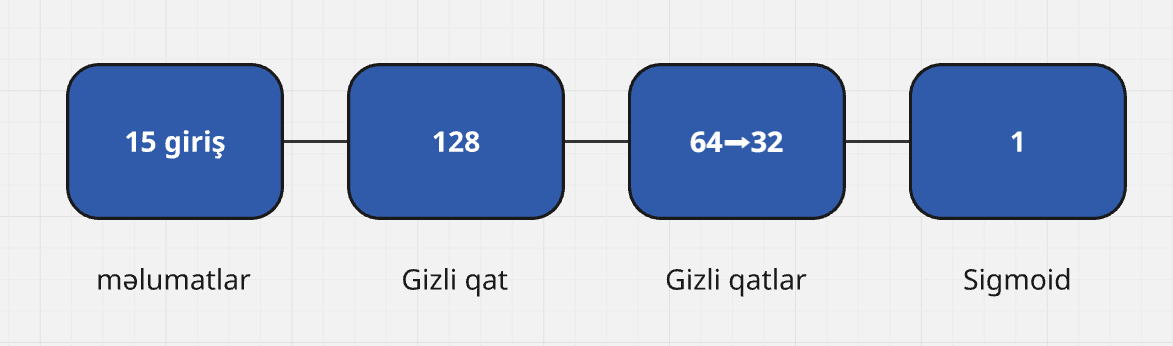

In [12]:
X = data.drop('TenYearCHD', axis=1)
y = data['TenYearCHD']

X = X.values.astype(np.float32)
y = y.values.astype(np.float32)

In [13]:
X.shape

(4238, 15)

In [14]:
y.shape

(4238,)

In [15]:
np.sum(y == 0), np.sum(y == 1)

(np.int64(3594), np.int64(644))

In [16]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [20]:
preprocessing_pipeline = Pipeline([\

    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
])

In [21]:
preprocessing_pipeline.fit(X_train)

X_train_scaled = preprocessing_pipeline.transform(X_train)
X_test_scaled = preprocessing_pipeline.transform(X_test)

In [22]:
X_train_scaled.shape, X_test_scaled.shape

((3390, 15), (848, 15))

In [23]:
np.isnan(X_train_scaled).sum()

np.int64(0)

In [24]:
np.isnan(X_test_scaled).sum()

np.int64(0)

In [26]:
for step_name, step_transformer in preprocessing_pipeline.steps:
    print(f'    - {step_name}: {type(step_transformer).__name__}')

    - imputer: SimpleImputer
    - scaler: StandardScaler


In [27]:
class HeartDiseaseDataset(Dataset):
    def __init__(self, features, labels):
        self.features = torch.FloatTensor(features)
        self.labels = torch.FloatTensor(labels)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        return self.features[index], self.labels[index]

In [28]:
train_dataset = HeartDiseaseDataset(X_train_scaled, y_train)
test_dataset = HeartDiseaseDataset(X_test_scaled, y_test)

In [29]:
train_loader = DataLoader(
    dataset=train_dataset,
    batch_size=64,
    shuffle=True,
)

test_loader = DataLoader(
    dataset=test_dataset,
    batch_size=64,
    shuffle=False,
)
len(train_loader), len(test_loader)

(53, 14)

In [37]:
class HeartDiseaseNet(nn.Module):
    def __init__(self, input_size):
        super(HeartDiseaseNet, self).__init__()

        self.fc1 = nn.Linear(input_size, 128)
        self.relu1 = nn.ReLU()

        self.fc2 = nn.Linear(128, 64)
        self.relu2 = nn.ReLU()

        self.fc3 = nn.Linear(64, 32)
        self.relu3 = nn.ReLU()

        self.dropout = nn.Dropout(0.3)

        self.fc4 = nn.Linear(32, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = self.fc1(x)
        x = self.relu1(x)

        x = self.fc2(x)
        x = self.relu2(x)

        x = self.fc3(x)
        x = self.relu3(x)

        x = self.dropout(x)

        x = self.fc4(x)
        x = self.sigmoid(x)

        return x

In [38]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')

Device: cpu


In [39]:
input_size = X_train_scaled.shape[1]
model = HeartDiseaseNet(input_size)

In [40]:
model = model.to(device)
print(f'Model architecture: {model}')

Model architecture: HeartDiseaseNet(
  (fc1): Linear(in_features=15, out_features=128, bias=True)
  (relu1): ReLU()
  (fc2): Linear(in_features=128, out_features=64, bias=True)
  (relu2): ReLU()
  (fc3): Linear(in_features=64, out_features=32, bias=True)
  (relu3): ReLU()
  (dropout): Dropout(p=0.3, inplace=False)
  (fc4): Linear(in_features=32, out_features=1, bias=True)
  (sigmoid): Sigmoid()
)


In [41]:
criterion = nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
print(f'Loss: {criterion}')
print(f'Optimizer: {optimizer}')

Loss: BCELoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [42]:
num_epoch = 50
train_losses = []
train_accuracy = []

for epoch in range(num_epoch):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    train_loop = tqdm(train_loader, desc=f'Epoch {epoch + 1}/ {num_epoch}')
    for batch_idx, (inputs, labels) in enumerate(train_loop):
        features, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()

        outputs = model(features)

        outputs = outputs.squeeze()

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        predicted = (outputs >= 0.5).float()

        total += labels.size(0)

        correct += (predicted == labels).sum().item()

        train_loop.set_postfix(
            {
                'loss': f'{loss.item():.4f}',
                'accuracy': f'{correct / total:.2f}'
            }
        )

        epoch_loss = running_loss / len(train_loader)
        epoch_accuracy = 100 * correct / total

        train_losses.append(epoch_loss)
        train_accuracy.append(epoch_accuracy)

        print(f'Epoch [{epoch + 1}/ {num_epoch}] Loss: {epoch_loss:.4f} Accuracy: {epoch_accuracy}]')
print('Finished training')

Epoch 1/ 50:  75%|███████▌  | 40/53 [00:00<00:00, 190.94it/s, loss=0.4201, accuracy=0.85]

Epoch [1/ 50] Loss: 0.0126 Accuracy: 81.25]
Epoch [1/ 50] Loss: 0.0249 Accuracy: 82.8125]
Epoch [1/ 50] Loss: 0.0369 Accuracy: 85.41666666666667]
Epoch [1/ 50] Loss: 0.0492 Accuracy: 84.375]
Epoch [1/ 50] Loss: 0.0611 Accuracy: 84.375]
Epoch [1/ 50] Loss: 0.0729 Accuracy: 84.63541666666667]
Epoch [1/ 50] Loss: 0.0843 Accuracy: 85.26785714285714]
Epoch [1/ 50] Loss: 0.0960 Accuracy: 84.765625]
Epoch [1/ 50] Loss: 0.1074 Accuracy: 84.72222222222223]
Epoch [1/ 50] Loss: 0.1190 Accuracy: 84.375]
Epoch [1/ 50] Loss: 0.1296 Accuracy: 85.08522727272727]
Epoch [1/ 50] Loss: 0.1407 Accuracy: 84.765625]
Epoch [1/ 50] Loss: 0.1511 Accuracy: 85.09615384615384]
Epoch [1/ 50] Loss: 0.1618 Accuracy: 85.04464285714286]
Epoch [1/ 50] Loss: 0.1714 Accuracy: 85.52083333333333]
Epoch [1/ 50] Loss: 0.1815 Accuracy: 85.64453125]
Epoch [1/ 50] Loss: 0.1914 Accuracy: 85.66176470588235]
Epoch [1/ 50] Loss: 0.2018 Accuracy: 85.59027777777777]
Epoch [1/ 50] Loss: 0.2111 Accuracy: 85.6907894736842]
Epoch [1/ 50] 

Epoch 1/ 50: 100%|██████████| 53/53 [00:00<00:00, 193.80it/s, loss=0.3686, accuracy=0.85]


Epoch [1/ 50] Loss: 0.4108 Accuracy: 84.85863095238095]
Epoch [1/ 50] Loss: 0.4210 Accuracy: 84.70203488372093]
Epoch [1/ 50] Loss: 0.4312 Accuracy: 84.55255681818181]
Epoch [1/ 50] Loss: 0.4400 Accuracy: 84.47916666666667]
Epoch [1/ 50] Loss: 0.4473 Accuracy: 84.47690217391305]
Epoch [1/ 50] Loss: 0.4544 Accuracy: 84.50797872340425]
Epoch [1/ 50] Loss: 0.4599 Accuracy: 84.63541666666667]
Epoch [1/ 50] Loss: 0.4681 Accuracy: 84.59821428571429]
Epoch [1/ 50] Loss: 0.4761 Accuracy: 84.5625]
Epoch [1/ 50] Loss: 0.4819 Accuracy: 84.71200980392157]
Epoch [1/ 50] Loss: 0.4886 Accuracy: 84.73557692307692]
Epoch [1/ 50] Loss: 0.4955 Accuracy: 84.80825958702064]


Epoch 2/ 50:  38%|███▊      | 20/53 [00:00<00:00, 194.25it/s, loss=0.4728, accuracy=0.84]

...

Epoch [50/ 50] Loss: 0.1418 Accuracy: 94.25951086956522]
Epoch [50/ 50] Loss: 0.1468 Accuracy: 94.21542553191489]


Epoch 50/ 50:  75%|███████▌  | 40/53 [00:00<00:00, 177.25it/s, loss=0.1651, accuracy=0.94]

Epoch [50/ 50] Loss: 0.1496 Accuracy: 94.20572916666667]


Epoch 50/ 50: 100%|██████████| 53/53 [00:00<00:00, 178.41it/s, loss=0.1600, accuracy=0.94]


Epoch [50/ 50] Loss: 0.1527 Accuracy: 94.19642857142857]
Epoch [50/ 50] Loss: 0.1544 Accuracy: 94.25]
Epoch [50/ 50] Loss: 0.1568 Accuracy: 94.30147058823529]
Epoch [50/ 50] Loss: 0.1628 Accuracy: 94.23076923076923]
Epoch [50/ 50] Loss: 0.1658 Accuracy: 94.15929203539822]
Finished training
